# Assignment 4 — Edge Computing & Intelligent Systems  (Kaggle GPU edition)
**Q1:** Knowledge Distillation (ResNet-50 → MobileNetV2 / SqueezeNet / EfficientNet-Lite0 on CIFAR-100) + ONNX Runtime CPU inference
**Q2:** Hardware-aware Neural Architecture Search (Optuna) on CIFAR-10 + ONNX Runtime CPU inference

**How to run (Kaggle):**
1. Create a new notebook → *File → Import notebook* and upload this file.
2. Right panel → **Session options**: *Accelerator* = **GPU T4 x2** (or P100) and **Internet = On** (needed to download CIFAR and the ImageNet-pretrained ResNet-50 weights).
3. *Run All* (or *Save & Run All (Commit)* to run in the background). Expected total runtime on a T4: **roughly 40–60 minutes** with the default budget.
4. For a ~3-minute smoke test of the whole pipeline set `QUICK = True` in the config cell.

Speed-ups versus the Colab-TPU version: **mixed-precision (fp16 autocast + GradScaler)**, channels-last tensors, cuDNN autotune, a ResNet-50 teacher that keeps its stem max-pool (4× cheaper), and a smaller epoch / NAS-trial budget (see the config cell). All *deployment* measurements (latency / size / memory / ONNX Runtime) run on the **CPU** of the Kaggle VM, as the assignment requires. Only one GPU is used.

Everything is saved under `assignment4_outputs/` (checkpoints, ONNX models, CSV/JSON results, figures, README) and zipped to `/kaggle/working/<ROLL>_<SECTION>.zip` (appears in the notebook *Output* tab).

## 0. Setup

In [5]:
%pip install -q onnx onnxruntime onnxscript optuna tabulate huggingface_hub pyarrow
import torch
print("torch", torch.__version__, "| CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("!! No GPU detected. Enable it: Session options -> Accelerator -> GPU. (The notebook will still run on CPU, very slowly - use QUICK=True.)")

Note: you may need to restart the kernel to use updated packages.
torch 2.11.0+cu130 | CUDA available: True
GPU: Tesla T4


In [6]:
import os
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")     # Kaggle T4 x2 -> use a single GPU (no DataParallel)
import sys, json, time, math, copy, io, gc, random, shutil, subprocess, zipfile, contextlib
from pathlib import Path
import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore", category=DeprecationWarning); warnings.filterwarnings("ignore", message=".*TracerWarning.*|.*Converting a tensor to a Python boolean.*")

def get_device():
    """CUDA GPU if present, else CPU."""
    if torch.cuda.is_available():
        torch.backends.cudnn.benchmark = True            # autotune conv kernels (static shapes)
        return torch.device("cuda"), "cuda"
    print("!! No GPU found -> running on CPU (use QUICK=True)")
    return torch.device("cpu"), "cpu"

DEV, BACKEND = get_device()
USE_AMP = BACKEND == "cuda"                              # fp16 autocast + GradScaler on GPU

def AMP_CTX():
    return torch.autocast("cuda", dtype=torch.float16) if USE_AMP else contextlib.nullcontext()

def sync():
    """No-op on CUDA (kept so the training loop is backend-agnostic)."""
    pass

T0 = time.time()
def tick(msg): print(f"\n>>> [{(time.time()-T0)/60:5.1f} min elapsed] {msg}\n")

print(f"torch {torch.__version__} | torchvision {torchvision.__version__}")
print(f"Training device : {DEV}  (backend = {BACKEND}, AMP = {USE_AMP})" + (f" | {torch.cuda.get_device_name(0)}" if USE_AMP else ""))
print(f"CPU cores on VM : {os.cpu_count()}")

torch 2.11.0+cu130 | torchvision 0.26.0+cu130
Training device : cuda  (backend = cuda, AMP = True) | Tesla T4
CPU cores on VM : 4


In [8]:
# =========================  CONFIGURATION (Kaggle T4 budget, ~40-60 min total)  =========================
# Raise TEACHER_EPOCHS / STUDENT_EPOCHS / N_TRIALS / FINAL_EPOCHS if you have spare session time (accuracy goes up).
QUICK = False            # True = tiny smoke-test run (minutes). False = full assignment run.

ROLL_NUM, SECTION = "21i-1713", "A"     # <-- edit if needed; used for the final zip name
SEED = 42

OUT = Path("assignment4_outputs")
CKPT, ONNX_DIR, RES_DIR, FIG_DIR = OUT/"checkpoints", OUT/"onnx", OUT/"results", OUT/"figures"
for d in (CKPT, ONNX_DIR, RES_DIR, FIG_DIR): d.mkdir(parents=True, exist_ok=True)
DATA_ROOT = "/tmp/data"            # keep datasets out of /kaggle/working (output size)

# ---- Q1: training budget
BATCH          = 64 if QUICK else 256
TEACHER_EPOCHS = 1  if QUICK else 6
STUDENT_EPOCHS = 1  if QUICK else 12
TRAIN_LIMIT    = 256 if QUICK else None     # use only N training images (QUICK mode)
TEST_LIMIT     = 500 if QUICK else None
LR_TEACHER, LR_STUDENT, WEIGHT_DECAY = 0.05, 0.1, 5e-4

# ---- Q1: knowledge-distillation hyper-parameters
KD_T      = 4.0   # softmax temperature
KD_ALPHA  = 0.7   # weight of soft (teacher) loss; hard-label CE gets (1 - alpha)
KD_BETA   = 1.0   # weight of feature-based distillation loss

# ---- Q2: NAS budget + deployment constraints (measured on CPU, batch=1, ONNX Runtime)
N_TRIALS         = 4 if QUICK else 14
NAS_EPOCHS       = 1 if QUICK else 3            # short proxy training per candidate
NAS_TRAIN_LIMIT  = 256 if QUICK else 15000
NAS_BATCH        = 64 if QUICK else 256
FINAL_EPOCHS     = 1 if QUICK else 20           # full training of the winning architecture
MAX_LATENCY_MS   = 10.0     # reject if mean CPU latency  > 10 ms
MAX_SIZE_MB      = 2.0      # reject if ONNX file size    > 2 MB
MAX_PEAK_MEM_MB  = 150.0    # reject if peak inference RSS growth > 150 MB
LAMBDA_LAT, LAMBDA_SIZE = 0.03, 0.03   # soft penalty weights inside the search objective

# ---- benchmarking
BENCH_RUNS, BENCH_THREADS = (20 if QUICK else 100), 1

def seed_all(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
seed_all()
print("QUICK mode:", QUICK)

QUICK mode: False


## 1. Data (downloaded inside the notebook)
CIFAR-100 is used for Q1 and CIFAR-10 for Q2. The whole dataset is kept as `uint8` arrays; augmentation (random-crop with 4-px reflect padding + horizontal flip) is done per epoch with vectorised NumPy, and batches are normalised **on the accelerator**. Every training batch has a fixed shape, which avoids XLA recompilation on TPU.

In [9]:
from torchvision.datasets import CIFAR10, CIFAR100

class Split:
    def __init__(self, X, Y): self.X, self.Y = X, Y
    def __len__(self): return len(self.X)
    def head(self, n): return Split(self.X[:n], self.Y[:n]) if n else self

STATS = {  # per-channel mean / std
    "cifar100": ((0.5071, 0.4865, 0.4409), (0.2673, 0.2564, 0.2762)),
    "cifar10" : ((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)),
}

def _load_hf(name):
    """Fast mirror: parquet files of the HuggingFace 'uoft-cs/cifar*' datasets (the toronto.edu server is often very slow from Kaggle)."""
    import io
    from PIL import Image
    import pyarrow.parquet as pq
    from huggingface_hub import list_repo_files, hf_hub_download
    repo = {"cifar100": "uoft-cs/cifar100", "cifar10": "uoft-cs/cifar10"}[name]
    files = [f for f in list_repo_files(repo, repo_type="dataset") if f.endswith(".parquet")]
    def read(key):
        X, Y, classes = [], [], None
        sel = sorted(f for f in files if f.split("/")[-1].startswith(key))
        assert sel, f"no {key} parquet in {repo}"
        for f in sel:
            p = hf_hub_download(repo, f, repo_type="dataset")
            t = pq.read_table(p); cols = t.column_names
            imgc = "img" if "img" in cols else "image"
            labc = "fine_label" if "fine_label" in cols else "label"
            if classes is None:
                try: classes = json.loads((pq.read_schema(p).metadata or {})[b"huggingface"])["info"]["features"][labc]["names"]
                except Exception: classes = None
            X += [np.array(Image.open(io.BytesIO(d["bytes"])).convert("RGB")) for d in t.column(imgc).to_pylist()]
            Y += t.column(labc).to_pylist()
        return np.stack(X).astype(np.uint8), np.array(Y, dtype=np.int64), classes
    (xtr, ytr, cls), (xte, yte, _) = read("train"), read("test")
    nc = 100 if name == "cifar100" else 10
    assert xtr.shape == (50000, 32, 32, 3) and xte.shape == (10000, 32, 32, 3) and ytr.max() == nc - 1, "unexpected dataset shape"
    return Split(xtr, ytr), Split(xte, yte), (cls or [str(i) for i in range(nc)])

def load_cifar(name):
    try:
        out = _load_hf(name); print(f"  {name}: loaded from HuggingFace mirror"); return out
    except Exception as e:
        print(f"  HF mirror failed ({repr(e)[:100]}) -> falling back to torchvision download (can be slow)")
    D = CIFAR100 if name == "cifar100" else CIFAR10
    tr, te = D(DATA_ROOT, train=True, download=True), D(DATA_ROOT, train=False, download=True)
    return (Split(tr.data, np.array(tr.targets, dtype=np.int64)),
            Split(te.data, np.array(te.targets, dtype=np.int64)), tr.classes)

_stat_cache = {}
def dev_stats(name):
    if name not in _stat_cache:
        m, s = STATS[name]
        _stat_cache[name] = (torch.tensor(m, device=DEV).view(1,3,1,1), torch.tensor(s, device=DEV).view(1,3,1,1))
    return _stat_cache[name]

def augment(X, rng, pad=4):
    """Vectorised random-crop (reflect pad) + horizontal flip on a uint8 NHWC array."""
    N, H, W, _ = X.shape
    P = np.pad(X, ((0,0),(pad,pad),(pad,pad),(0,0)), mode="reflect")
    iy, ix = rng.integers(0, 2*pad+1, N), rng.integers(0, 2*pad+1, N)
    ar = np.arange(H)
    out = P[np.arange(N)[:,None,None], (iy[:,None]+ar)[:,:,None], (ix[:,None]+ar)[:,None,:]]
    flip = rng.random(N) < 0.5
    out[flip] = out[flip][:, :, ::-1]
    return out

def to_dev(xb, yb, ds):
    mean, std = dev_stats(ds)
    x = torch.from_numpy(np.ascontiguousarray(xb)).to(DEV).permute(0,3,1,2).float().div(255.0)
    x = (x - mean) / std
    if BACKEND == "cuda": x = x.contiguous(memory_format=torch.channels_last)
    return x, torch.from_numpy(yb).to(DEV)

def train_batches(split, bs, ds, rng):
    perm = rng.permutation(len(split))
    X, Y = augment(split.X[perm], rng), split.Y[perm]
    for i in range(0, len(X) // bs * bs, bs):          # drop_last -> static shapes
        yield to_dev(X[i:i+bs], Y[i:i+bs], ds)

print("Downloading CIFAR-100 ..."); C100_TR, C100_TE, C100_CLASSES = load_cifar("cifar100")
print("Downloading CIFAR-10  ..."); C10_TR,  C10_TE,  C10_CLASSES  = load_cifar("cifar10")
C100_TR, C100_TE = C100_TR.head(TRAIN_LIMIT), C100_TE.head(TEST_LIMIT)

# CIFAR-10: fixed 45k / 5k train / validation split for NAS; official 10k test set for the final model
_perm = np.random.default_rng(SEED).permutation(len(C10_TR))
_nval = 500 if QUICK else 5000
C10_VAL  = Split(C10_TR.X[_perm[:_nval]], C10_TR.Y[_perm[:_nval]])
C10_TRN  = Split(C10_TR.X[_perm[_nval:]], C10_TR.Y[_perm[_nval:]])
C10_FULL = C10_TR if not QUICK else C10_TRN.head(TRAIN_LIMIT)
C10_TE   = C10_TE.head(TEST_LIMIT)
print(f"CIFAR-100: train {len(C100_TR)}  test {len(C100_TE)} | CIFAR-10: train {len(C10_TRN)}  val {len(C10_VAL)}  test {len(C10_TE)}")

json.dump(C100_CLASSES, open(RES_DIR/"classes_cifar100.json","w"))
json.dump(C10_CLASSES,  open(RES_DIR/"classes_cifar10.json","w"))

cifar100/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  119MB            

cifar100/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

cifar100/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.8MB            

cifar100/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

  cifar100: loaded from HuggingFace mirror


plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

  cifar10: loaded from HuggingFace mirror
CIFAR-100: train 50000  test 10000 | CIFAR-10: train 45000  val 5000  test 10000


## 2. Training engine (shared by every experiment)
* **`TensorSGD`** — SGD + Nesterov momentum (no weight decay on BN / bias) whose learning-rate is a device tensor, so the cosine schedule needs no re-creation of the optimizer.
* **`fit`** — generic loop: linear warm-up + cosine decay, **fp16 autocast + GradScaler**, channels-last, per-epoch test accuracy.
* **`evaluate`** — batched accuracy under autocast; the last partial batch is padded so shapes stay static.

In [11]:
class TensorSGD(torch.optim.Optimizer):
    def __init__(self, params, momentum=0.9, weight_decay=5e-4, nesterov=True):
        super().__init__(params, dict(momentum=momentum, weight_decay=weight_decay, nesterov=nesterov))
        self.lr_t = None
    def set_lr(self, lr): self.lr_t = torch.tensor(float(lr), dtype=torch.float32, device=DEV)
    @torch.no_grad()
    def step(self):
        for g in self.param_groups:
            for p in g["params"]:
                if p.grad is None: continue
                d = p.grad
                if g["weight_decay"] and p.ndim > 1:           # no weight decay on BN / bias
                    d = d + g["weight_decay"] * p
                st = self.state[p]
                if "buf" not in st: st["buf"] = torch.zeros_like(p)
                buf = st["buf"].mul_(g["momentum"]).add_(d)
                p.sub_(self.lr_t * (d + g["momentum"] * buf if g["nesterov"] else buf))

def lr_at(step, total, base, warm):
    if step < warm: return base * (step + 1) / warm
    return 0.5 * base * (1 + math.cos(math.pi * (step - warm) / max(1, total - warm)))

@torch.no_grad()
def evaluate(model, split, ds, bs=None):
    bs = bs or (100 if QUICK else 500)
    model.eval()
    corr = torch.zeros((), dtype=torch.long, device=DEV)
    for i in range(0, len(split), bs):
        xb, yb = split.X[i:i+bs], split.Y[i:i+bs]
        m = len(xb)
        if m < bs:                                      # pad last batch -> static shape
            xb = np.concatenate([xb, np.repeat(xb[:1], bs-m, 0)]); yb = np.concatenate([yb, np.repeat(yb[:1], bs-m, 0)])
        x, y = to_dev(xb, yb, ds)
        with AMP_CTX(): out = model(x)
        corr += (out.argmax(1)[:m] == y[:m]).sum()
    return 100.0 * corr.item() / len(split)

def fit(model, loss_fn, train_split, test_split, ds, epochs, base_lr, bs, tag, extra_modules=(), wd=WEIGHT_DECAY):
    """loss_fn(x, y) -> (loss, student_logits). Returns a list of per-epoch dicts."""
    mods = [model, *extra_modules]
    if BACKEND == "cuda":
        for m in mods: m.to(memory_format=torch.channels_last)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    opt = TensorSGD([p for m in mods for p in m.parameters()], weight_decay=wd)
    spe = len(train_split) // bs
    total, warm = spe * epochs, max(1, spe)             # 1 epoch warm-up
    rng, step, hist = np.random.default_rng(SEED), 0, []
    t0 = time.time()
    for ep in range(epochs):
        for m in mods: m.train()
        loss_acc = torch.zeros((), device=DEV); corr = torch.zeros((), dtype=torch.long, device=DEV); n = 0
        for x, y in train_batches(train_split, bs, ds, rng):
            opt.set_lr(lr_at(step, total, base_lr, warm))
            with AMP_CTX():
                loss, logits = loss_fn(x, y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            loss_acc += loss.detach(); corr += (logits.detach().argmax(1) == y).sum(); n += bs; step += 1
        te = evaluate(model, test_split, ds)
        rec = dict(tag=tag, epoch=ep+1, train_loss=loss_acc.item()/max(1,spe), train_acc=100*corr.item()/max(1,n),
                   test_acc=te, elapsed_s=round(time.time()-t0, 1))
        hist.append(rec)
        print(f"[{tag}] ep {ep+1:>2}/{epochs}  loss {rec['train_loss']:.3f}  train {rec['train_acc']:.1f}%  test {te:.2f}%  ({rec['elapsed_s']}s)")
    return hist

def count_params(m): return sum(p.numel() for p in m.parameters())

def save_ckpt(model, path):
    torch.save({k: v.detach().cpu() for k, v in model.state_dict().items()}, path)

# Question 1 — Knowledge Distillation
## 3. Teacher (ResNet-50) and the three student architectures
All networks are adapted to 32×32 CIFAR images (stride-1 3×3 stem, fewer down-sampling steps) and expose the same interface:

`model(x)` → logits  |  `model(x, feats=True)` → `(logits, [mid_feature_map, final_feature_map])`

The two returned feature maps are the *intermediate representations* used by feature-based distillation.

* **Teacher:** torchvision ResNet-50 (ImageNet-pretrained body, new CIFAR stem and 100-way head), taps = `layer3` (1024 ch) and `layer4` (2048 ch).
* **MobileNetV2** and **EfficientNet-Lite0** are written from scratch with one shared inverted-residual (MBConv) builder. MobileNetV2 = ReLU6, 3×3 kernels. EfficientNet-Lite0 = the official B0 stage table (3×3 / 5×5 kernels), ReLU6 and **no squeeze-excite** (the "Lite" modification).
* **SqueezeNet** is written from scratch from Fire modules (squeeze 1×1 → expand 1×1 ‖ 3×3) with BatchNorm and a fully-convolutional classifier.

*Kaggle note:* to fit a short GPU budget the teacher keeps ResNet-50's stem max-pool (teacher taps are therefore 4×4 and 2×2 maps); the feature-distillation adapters average-pool the student maps to whatever spatial size the teacher produces, so nothing else changes.

In [12]:
# ------------------------------ Teacher: ResNet-50 ------------------------------
class TeacherResNet50(nn.Module):
    def __init__(self, num_classes=100, pretrained=True):
        super().__init__()
        try:
            m = torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.IMAGENET1K_V2 if pretrained else None)
            if pretrained: print("Loaded ImageNet-pretrained ResNet-50 weights.")
        except Exception as e:
            print("!! pretrained weights unavailable (", repr(e)[:80], ") -> training from random init"); m = torchvision.models.resnet50(weights=None)
        m.conv1 = nn.Conv2d(3, 64, 3, 1, 1, bias=False)         # CIFAR stem: 3x3, stride 1
        # max-pool is KEPT (feature maps 16x16 -> 8x8 -> 4x4 -> 2x2): ~4x cheaper than the full-res CIFAR variant, ideal for a short GPU budget
        m.fc = nn.Linear(2048, num_classes)
        self.m = m
        self.feat_channels = (1024, 2048)
    def forward(self, x, feats=False):
        m = self.m
        x = m.relu(m.bn1(m.conv1(x)))
        x = m.layer2(m.layer1(x)); f3 = m.layer3(x); f4 = m.layer4(f3)
        out = m.fc(torch.flatten(m.avgpool(f4), 1))
        return (out, [f3, f4]) if feats else out

# ------------------- MobileNetV2 / EfficientNet-Lite0 (MBConv family) -------------------
class ConvBNAct(nn.Sequential):
    def __init__(self, i, o, k=3, s=1, groups=1, act=True):
        super().__init__(nn.Conv2d(i, o, k, s, k // 2, groups=groups, bias=False), nn.BatchNorm2d(o),
                         *([nn.ReLU6()] if act else []))

class InvertedResidual(nn.Module):
    def __init__(self, i, o, k, s, expand):
        super().__init__()
        mid, layers = i * expand, []
        if expand != 1: layers.append(ConvBNAct(i, mid, 1))                  # expansion 1x1
        layers += [ConvBNAct(mid, mid, k, s, groups=mid),                    # depthwise kxk
                   ConvBNAct(mid, o, 1, act=False)]                          # linear projection
        self.block, self.use_res = nn.Sequential(*layers), (s == 1 and i == o)
    def forward(self, x):
        y = self.block(x)
        return x + y if self.use_res else y

class MBConvNet(nn.Module):
    """stages: list of (expand_ratio, kernel, out_channels, repeats, stride)."""
    def __init__(self, stages, stem_c=32, head_c=1280, num_classes=100, mid_stage=4, dropout=0.2):
        super().__init__()
        self.stem = ConvBNAct(3, stem_c, 3, 1)                               # stride 1 for 32x32 input
        self.stages, c = nn.ModuleList(), stem_c
        for (t, k, cout, n, s) in stages:
            self.stages.append(nn.Sequential(*[InvertedResidual(c if j == 0 else cout, cout, k, s if j == 0 else 1, t) for j in range(n)]))
            c = cout
        self.head = ConvBNAct(c, head_c, 1)
        self.drop, self.fc = nn.Dropout(dropout), nn.Linear(head_c, num_classes)
        self.mid_stage, self.feat_channels = mid_stage, (stages[mid_stage][2], head_c)
        for m in self.modules():
            if isinstance(m, nn.Conv2d): nn.init.kaiming_normal_(m.weight, mode="fan_out")
    def forward(self, x, feats=False):
        x, mid = self.stem(x), None
        for i, st in enumerate(self.stages):
            x = st(x)
            if i == self.mid_stage: mid = x
        f = self.head(x)
        out = self.fc(self.drop(f.mean((2, 3))))
        return (out, [mid, f]) if feats else out

#                  (expand, kernel, out_c, repeats, stride)   [stage-2 stride 1 -> CIFAR adaptation]
MBV2_STAGES = [(1,3,16,1,1), (6,3,24,2,1), (6,3,32,3,2), (6,3,64,4,2), (6,3,96,3,1), (6,3,160,3,2), (6,3,320,1,1)]
LITE0_STAGES = [(1,3,16,1,1), (6,3,24,2,1), (6,5,40,2,2), (6,3,80,3,2), (6,5,112,3,1), (6,5,192,4,2), (6,3,320,1,1)]

# ------------------------------------ SqueezeNet ------------------------------------
def cba(i, o, k): return nn.Sequential(nn.Conv2d(i, o, k, 1, k // 2, bias=False), nn.BatchNorm2d(o), nn.ReLU())

class Fire(nn.Module):
    def __init__(self, i, sq, e1, e3):
        super().__init__()
        self.squeeze, self.e1, self.e3 = cba(i, sq, 1), cba(sq, e1, 1), cba(sq, e3, 3)
    def forward(self, x):
        s = self.squeeze(x)
        return torch.cat([self.e1(s), self.e3(s)], 1)

class SqueezeNet(nn.Module):
    def __init__(self, num_classes=100, dropout=0.2):
        super().__init__()
        self.stem = cba(3, 64, 3)
        self.f1 = nn.Sequential(Fire(64,16,64,64), Fire(128,16,64,64), nn.MaxPool2d(2))                 # -> 16x16
        self.f2 = nn.Sequential(Fire(128,32,128,128), Fire(256,32,128,128), nn.MaxPool2d(2))            # -> 8x8
        self.f3a = nn.Sequential(Fire(256,48,192,192), Fire(384,48,192,192))                            # mid tap (384 ch)
        self.f3b = nn.Sequential(Fire(384,64,256,256), Fire(512,64,256,256))                            # final tap (512 ch)
        self.drop, self.cls = nn.Dropout(dropout), nn.Conv2d(512, num_classes, 1)                        # fully-convolutional head
        self.feat_channels = (384, 512)
        for m in self.modules():
            if isinstance(m, nn.Conv2d): nn.init.kaiming_normal_(m.weight, mode="fan_out")
    def forward(self, x, feats=False):
        x = self.f2(self.f1(self.stem(x)))
        mid = self.f3a(x); f = self.f3b(mid)
        out = self.cls(self.drop(f)).mean((2, 3))
        return (out, [mid, f]) if feats else out

STUDENTS = {
    "mobilenetv2":        lambda nc=100: MBConvNet(MBV2_STAGES,  num_classes=nc),
    "squeezenet":         lambda nc=100: SqueezeNet(num_classes=nc),
    "efficientnet_lite0": lambda nc=100: MBConvNet(LITE0_STAGES, num_classes=nc),
}
def build_student(name, nc=100): return STUDENTS[name](nc)

_t = TeacherResNet50(pretrained=False)
print(f"{'resnet50 (teacher)':<22}{count_params(_t)/1e6:6.2f} M params")
for n in STUDENTS:
    s = build_student(n); lg, fs = s(torch.randn(2,3,32,32), feats=True)
    print(f"{n:<22}{count_params(s)/1e6:6.2f} M params | logits {tuple(lg.shape)} | mid {tuple(fs[0].shape)} | final {tuple(fs[1].shape)}")
del _t, s

resnet50 (teacher)     23.71 M params
mobilenetv2             2.35 M params | logits (2, 100) | mid (2, 96, 8, 8) | final (2, 1280, 4, 4)
squeezenet              0.78 M params | logits (2, 100) | mid (2, 384, 8, 8) | final (2, 512, 8, 8)
efficientnet_lite0      3.50 M params | logits (2, 100) | mid (2, 112, 8, 8) | final (2, 1280, 4, 4)


## 4. Train the teacher (ResNet-50, CIFAR-100)

In [13]:
seed_all()
teacher = TeacherResNet50(100, pretrained=True).to(DEV)
def teacher_loss(x, y):
    out = teacher(x); return F.cross_entropy(out, y), out

hist_teacher = fit(teacher, teacher_loss, C100_TR, C100_TE, "cifar100", TEACHER_EPOCHS, LR_TEACHER, BATCH, "teacher_resnet50")
save_ckpt(teacher, CKPT/"teacher_resnet50.pt")
pd.DataFrame(hist_teacher).to_csv(RES_DIR/"teacher_training_log.csv", index=False)
TEACHER_ACC = hist_teacher[-1]["test_acc"]
print(f"\nTeacher ResNet-50 final CIFAR-100 test accuracy: {TEACHER_ACC:.2f}%")
teacher.eval()
for p in teacher.parameters(): p.requires_grad_(False)
tick("teacher trained")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 191MB/s] 


Loaded ImageNet-pretrained ResNet-50 weights.
[teacher_resnet50] ep  1/6  loss 2.709  train 36.2%  test 67.16%  (53.9s)
[teacher_resnet50] ep  2/6  loss 0.821  train 75.5%  test 75.47%  (105.9s)
[teacher_resnet50] ep  3/6  loss 0.505  train 84.3%  test 80.53%  (161.9s)
[teacher_resnet50] ep  4/6  loss 0.302  train 90.2%  test 83.66%  (217.1s)
[teacher_resnet50] ep  5/6  loss 0.162  train 94.7%  test 84.71%  (272.1s)
[teacher_resnet50] ep  6/6  loss 0.107  train 96.8%  test 85.13%  (327.5s)

Teacher ResNet-50 final CIFAR-100 test accuracy: 85.13%

>>> [  6.7 min elapsed] teacher trained



## 5. Baseline pipeline (students trained **without** distillation)
Hard-label cross-entropy only, identical optimiser / schedule / epochs / augmentation as the distilled runs so the comparison is fair.

In [14]:
STUDENT_NAMES = list(STUDENTS)
ALL_LOGS, STUDENT_ACC = [], {}          # STUDENT_ACC[(arch, variant)] = final test acc

def train_baseline(name):
    """Separate baseline pipeline: plain cross-entropy, no teacher involved."""
    seed_all()
    s = build_student(name).to(DEV)
    def loss_fn(x, y):
        out = s(x); return F.cross_entropy(out, y), out
    h = fit(s, loss_fn, C100_TR, C100_TE, "cifar100", STUDENT_EPOCHS, LR_STUDENT, BATCH, f"baseline_{name}")
    save_ckpt(s, CKPT/f"baseline_{name}.pt")
    return h

for n in STUDENT_NAMES:
    h = train_baseline(n); ALL_LOGS += h; STUDENT_ACC[(n, "baseline")] = h[-1]["test_acc"]
pd.DataFrame(ALL_LOGS).to_csv(RES_DIR/"student_training_logs.csv", index=False)
print({k: round(v, 2) for k, v in STUDENT_ACC.items()})
tick("3 baseline students trained")

[baseline_mobilenetv2] ep  1/12  loss 4.127  train 6.9%  test 11.75%  (41.5s)
[baseline_mobilenetv2] ep  2/12  loss 3.187  train 21.5%  test 26.56%  (63.7s)
[baseline_mobilenetv2] ep  3/12  loss 2.588  train 32.9%  test 32.63%  (85.3s)
[baseline_mobilenetv2] ep  4/12  loss 2.205  train 40.9%  test 41.76%  (107.0s)
[baseline_mobilenetv2] ep  5/12  loss 1.939  train 46.5%  test 46.40%  (128.9s)
[baseline_mobilenetv2] ep  6/12  loss 1.732  train 51.6%  test 52.91%  (150.8s)
[baseline_mobilenetv2] ep  7/12  loss 1.544  train 56.1%  test 56.20%  (172.8s)
[baseline_mobilenetv2] ep  8/12  loss 1.376  train 60.5%  test 59.17%  (194.7s)
[baseline_mobilenetv2] ep  9/12  loss 1.213  train 64.7%  test 61.63%  (216.5s)
[baseline_mobilenetv2] ep 10/12  loss 1.074  train 68.6%  test 63.72%  (238.3s)
[baseline_mobilenetv2] ep 11/12  loss 0.969  train 71.4%  test 64.81%  (260.2s)
[baseline_mobilenetv2] ep 12/12  loss 0.916  train 73.1%  test 65.01%  (282.1s)
[baseline_squeezenet] ep  1/12  loss 4.046  

## 6. Knowledge-distillation framework
For a student with logits $z_s$, teacher logits $z_t$, labels $y$, temperature $T$:

$$\mathcal{L} = \alpha\,T^{2}\,\mathrm{KL}\big(\mathrm{softmax}(z_t/T)\,\|\,\mathrm{softmax}(z_s/T)\big) + (1-\alpha)\,\mathrm{CE}(z_s, y) + \beta\,\mathcal{L}_{feat}$$

* **Soft targets + temperature softmax:** the KL term (scaled by $T^2$ to keep gradient magnitude independent of $T$).
* **Combined hard + soft training:** the $\alpha$ / $(1-\alpha)$ mixture.
* **Feature-based distillation (FitNets-style):** for each tapped pair (student mid → teacher `layer3`, student final → teacher `layer4`) the student map is average-pooled to the teacher's spatial size, passed through a learnable 1×1 conv + BN *adapter* (to match channels) and compared to the teacher map with MSE. The teacher map is divided by its RMS so the loss is scale-free. Adapters exist only during training and are **not** part of the exported student.

In [15]:
class FeatureAdapters(nn.Module):
    """1x1-conv + BN regressors mapping student feature maps to teacher feature channels."""
    def __init__(self, student_ch, teacher_ch):
        super().__init__()
        self.adapt = nn.ModuleList([nn.Sequential(nn.Conv2d(s, t, 1, bias=False), nn.BatchNorm2d(t)) for s, t in zip(student_ch, teacher_ch)])
    def forward(self, s_feats, t_feats):
        loss = 0.0
        for a, sf, tf in zip(self.adapt, s_feats, t_feats):
            sf = F.adaptive_avg_pool2d(sf, tf.shape[-2:])                 # match spatial size
            tf = tf.float(); tf = tf / (tf.pow(2).mean().sqrt() + 1e-6)                    # scale-free target
            loss = loss + F.mse_loss(a(sf).float(), tf)
        return loss / len(s_feats)

def kd_logit_loss(s_logits, t_logits, y, T=KD_T, alpha=KD_ALPHA):
    soft = F.kl_div(F.log_softmax(s_logits.float() / T, 1), F.softmax(t_logits.float() / T, 1), reduction="batchmean") * (T * T)
    hard = F.cross_entropy(s_logits.float(), y)
    return alpha * soft + (1 - alpha) * hard, soft, hard

def train_with_kd(name, T=KD_T, alpha=KD_ALPHA, beta=KD_BETA, tag=None):
    seed_all()
    tag = tag or f"kd_{name}"
    s = build_student(name).to(DEV)
    adapters = FeatureAdapters(s.feat_channels, teacher.feat_channels).to(DEV) if beta > 0 else None
    def loss_fn(x, y):
        with torch.no_grad():
            t_logits, t_feats = teacher(x, feats=True)
        s_logits, s_feats = s(x, feats=True)
        loss, _, _ = kd_logit_loss(s_logits, t_logits, y, T, alpha)
        if adapters is not None: loss = loss + beta * adapters(s_feats, t_feats)
        return loss, s_logits
    h = fit(s, loss_fn, C100_TR, C100_TE, "cifar100", STUDENT_EPOCHS, LR_STUDENT, BATCH, tag,
            extra_modules=[adapters] if adapters is not None else [])
    save_ckpt(s, CKPT/f"{tag}.pt")
    return h

for n in STUDENT_NAMES:
    h = train_with_kd(n); ALL_LOGS += h; STUDENT_ACC[(n, "kd")] = h[-1]["test_acc"]
pd.DataFrame(ALL_LOGS).to_csv(RES_DIR/"student_training_logs.csv", index=False)
tick("3 distilled students trained")

[kd_mobilenetv2] ep  1/12  loss 12.935  train 8.0%  test 10.89%  (45.0s)
[kd_mobilenetv2] ep  2/12  loss 9.946  train 23.7%  test 25.99%  (88.0s)
[kd_mobilenetv2] ep  3/12  loss 7.772  train 36.8%  test 37.35%  (131.9s)
[kd_mobilenetv2] ep  4/12  loss 6.435  train 45.2%  test 42.51%  (175.5s)
[kd_mobilenetv2] ep  5/12  loss 5.437  train 51.1%  test 49.65%  (219.3s)
[kd_mobilenetv2] ep  6/12  loss 4.739  train 56.3%  test 56.71%  (263.2s)
[kd_mobilenetv2] ep  7/12  loss 4.235  train 60.7%  test 59.01%  (306.8s)
[kd_mobilenetv2] ep  8/12  loss 3.833  train 63.9%  test 63.07%  (350.5s)
[kd_mobilenetv2] ep  9/12  loss 3.429  train 67.6%  test 64.47%  (394.4s)
[kd_mobilenetv2] ep 10/12  loss 3.154  train 70.3%  test 66.43%  (438.2s)
[kd_mobilenetv2] ep 11/12  loss 2.957  train 72.7%  test 67.34%  (481.9s)
[kd_mobilenetv2] ep 12/12  loss 2.855  train 74.2%  test 67.74%  (525.5s)
[kd_squeezenet] ep  1/12  loss 12.517  train 10.7%  test 15.51%  (33.9s)
[kd_squeezenet] ep  2/12  loss 9.546  tra

Teacher (ResNet-50) accuracy: 85.13%   [23.7 M params]



,student,params_M,baseline_acc,kd_acc,kd_gain
0,mobilenetv2,2.352,65.01,67.74,2.73
1,squeezenet,0.777,62.40,63.65,1.25
2,efficientnet_lite0,3.499,66.35,68.86,2.51


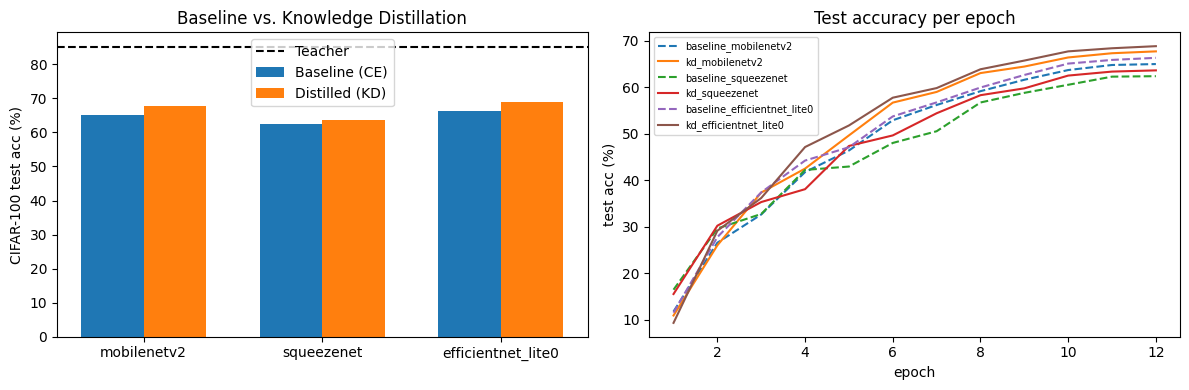

In [16]:
# ---- Baseline vs. distilled comparison
rows = [dict(student=n, params_M=round(count_params(build_student(n))/1e6, 3),
             baseline_acc=STUDENT_ACC[(n,"baseline")], kd_acc=STUDENT_ACC[(n,"kd")],
             kd_gain=round(STUDENT_ACC[(n,"kd")] - STUDENT_ACC[(n,"baseline")], 2)) for n in STUDENT_NAMES]
cmp_df = pd.DataFrame(rows); cmp_df.to_csv(RES_DIR/"kd_vs_baseline.csv", index=False)
print(f"Teacher (ResNet-50) accuracy: {TEACHER_ACC:.2f}%   [{count_params(teacher)/1e6:.1f} M params]\n")
display(cmp_df)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
w = 0.35; xs = np.arange(len(STUDENT_NAMES))
ax[0].bar(xs - w/2, cmp_df.baseline_acc, w, label="Baseline (CE)"); ax[0].bar(xs + w/2, cmp_df.kd_acc, w, label="Distilled (KD)")
ax[0].axhline(TEACHER_ACC, color="k", ls="--", label="Teacher"); ax[0].set_xticks(xs); ax[0].set_xticklabels(STUDENT_NAMES)
ax[0].set_ylabel("CIFAR-100 test acc (%)"); ax[0].set_title("Baseline vs. Knowledge Distillation"); ax[0].legend()
lg = pd.DataFrame(ALL_LOGS)
for n in STUDENT_NAMES:
    for v in ("baseline", "kd"):
        d = lg[lg.tag == f"{v}_{n}"]; ax[1].plot(d.epoch, d.test_acc, ls="-" if v == "kd" else "--", label=f"{v}_{n}")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("test acc (%)"); ax[1].set_title("Test accuracy per epoch"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIG_DIR/"q1_kd_vs_baseline.png", dpi=150); plt.show()

## 7. ONNX export, ONNX Runtime CPU inference and CPU benchmarking utilities
* `export_onnx` — exports any model (on CPU) to ONNX with a dynamic batch axis.
* `benchmark_onnx.py` — a standalone script (also a deliverable). It is run in a **fresh subprocess** so that latency and peak-memory readings are not disturbed by the TPU/XLA threads in the notebook process. It reports mean/median/p95 latency (batch 1, `BENCH_THREADS` threads) and the peak RSS growth during inference.
* `ort_accuracy` — full test-set accuracy through ONNX Runtime (CPU).

In [18]:
%%writefile benchmark_onnx.py
"""CPU benchmark of an ONNX model with ONNX Runtime.
Usage: python benchmark_onnx.py model.onnx [--runs 200] [--warmup 30] [--threads 1] [--batch 1] [--res 32]
Prints one JSON line: latency (mean/median/p95/std, ms), throughput, peak memory (RSS growth + absolute)."""
import argparse, json, os, time
import numpy as np

def _status_mb(key):
    with open("/proc/self/status") as f:
        for line in f:
            if line.startswith(key): return int(line.split()[1]) / 1024.0      # kB -> MB
    return 0.0

def rss_mb(): return _status_mb("VmRSS:")
def hwm_mb(): return _status_mb("VmHWM:")   # peak RSS of THIS process (reset on exec, unlike ru_maxrss which a fork inherits)

def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("model"); ap.add_argument("--runs", type=int, default=200); ap.add_argument("--warmup", type=int, default=30)
    ap.add_argument("--threads", type=int, default=1); ap.add_argument("--batch", type=int, default=1); ap.add_argument("--res", type=int, default=32)
    a = ap.parse_args()
    import onnxruntime as ort
    base = rss_mb()
    so = ort.SessionOptions(); so.intra_op_num_threads = a.threads; so.inter_op_num_threads = 1
    so.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL
    sess = ort.InferenceSession(a.model, so, providers=["CPUExecutionProvider"])
    name = sess.get_inputs()[0].name
    x = np.random.rand(a.batch, 3, a.res, a.res).astype(np.float32)
    for _ in range(a.warmup): sess.run(None, {name: x})
    ts = []
    for _ in range(a.runs):
        t = time.perf_counter(); sess.run(None, {name: x}); ts.append((time.perf_counter() - t) * 1e3)
    ts = np.array(ts); peak = hwm_mb()
    print(json.dumps(dict(lat_mean_ms=float(ts.mean()), lat_median_ms=float(np.median(ts)), lat_p95_ms=float(np.percentile(ts, 95)),
                          lat_std_ms=float(ts.std()), throughput_ips=float(a.batch * 1000.0 / ts.mean()),
                          peak_mem_mb=float(max(peak - base, 0.0)), peak_rss_mb=float(peak),
                          threads=a.threads, batch=a.batch, runs=a.runs)))
main()

Overwriting benchmark_onnx.py


In [19]:
import onnxruntime as ort

def export_onnx(model, path, res=32):
    """Export a model to ONNX (always from a CPU copy, eval mode, dynamic batch)."""
    m = copy.deepcopy(model).cpu().float().eval().to(memory_format=torch.contiguous_format)
    dummy = torch.randn(1, 3, res, res)
    kw = dict(input_names=["input"], output_names=["logits"], dynamic_axes={"input": {0: "batch"}, "logits": {0: "batch"}}, opset_version=17)
    try:
        torch.onnx.export(m, dummy, str(path), dynamo=False, **kw)       # classic TorchScript exporter
    except Exception as e:
        print("legacy exporter failed (", repr(e)[:80], ") -> trying dynamo exporter")
        torch.onnx.export(m, dummy, str(path), dynamo=True, **{k: v for k, v in kw.items() if k != "dynamic_axes"})
    return Path(path)

def bench_onnx(path, runs=None, threads=None):
    r = subprocess.run([sys.executable, "benchmark_onnx.py", str(path), "--runs", str(runs or BENCH_RUNS),
                        "--threads", str(threads or BENCH_THREADS)], capture_output=True, text=True)
    if r.returncode != 0: raise RuntimeError(r.stderr[-500:])
    return json.loads(r.stdout.strip().splitlines()[-1])

def ort_session(path, threads=None):
    so = ort.SessionOptions(); so.intra_op_num_threads = threads or (os.cpu_count() or 2)
    return ort.InferenceSession(str(path), so, providers=["CPUExecutionProvider"])

def np_normalize(xb, ds):
    m, s = STATS[ds]
    x = xb.astype(np.float32) / 255.0
    return np.ascontiguousarray(((x - np.array(m, np.float32)) / np.array(s, np.float32)).transpose(0, 3, 1, 2))

def ort_accuracy(path, split, ds, bs=250):
    sess = ort_session(path); name = sess.get_inputs()[0].name; corr = 0
    for i in range(0, len(split), bs):
        out = sess.run(None, {name: np_normalize(split.X[i:i+bs], ds)})[0]
        corr += int((out.argmax(1) == split.Y[i:i+bs]).sum())
    return 100.0 * corr / len(split)

def parity(model, path, ds, split, n=16):
    """Max |logit difference| between PyTorch-CPU and ONNX Runtime on n real test images."""
    m = copy.deepcopy(model).cpu().eval(); x = np_normalize(split.X[:n], ds)
    with torch.no_grad(): a = m(torch.from_numpy(x)).numpy()
    b = ort_session(path).run(None, {"input": x})[0]
    return float(np.abs(a - b).max())

def load_student_cpu(name, variant, nc=100):
    m = build_student(name, nc); m.load_state_dict(torch.load(CKPT/f"{variant}_{name}.pt", map_location="cpu")); return m.eval()

## 8. Unified inference pipeline (all students — and later the NAS model)
One class, one interface, two back-ends:
* `backend="torch"` — loads a `.pt` checkpoint, runs on CPU with PyTorch.
* `backend="onnx"` — loads a `.onnx` file, runs on CPU with ONNX Runtime.

`pipe.predict(images)` accepts file paths, PIL images or NumPy arrays (any size / any number), resizes to 32×32, normalises, and returns the top-k labels with probabilities.

In [20]:
from PIL import Image

class InferencePipeline:
    """Unified CPU inference for every trained model (3 baseline + 3 distilled students + NAS model)."""
    def __init__(self, arch, variant="kd", backend="onnx", nas_cfg=None):
        self.arch, self.variant, self.backend = arch, variant, backend
        self.ds = "cifar10" if arch == "nas" else "cifar100"
        self.classes = json.load(open(RES_DIR / f"classes_{self.ds}.json"))
        stem = f"{variant}_{arch}" if arch != "nas" else "nas_best"
        if backend == "onnx":
            self.sess = ort_session(ONNX_DIR / f"{stem}.onnx"); self.in_name = self.sess.get_inputs()[0].name
        else:
            if arch == "nas":
                self.model = NASNet(nas_cfg or json.load(open(RES_DIR/"best_architecture.json"))["config"], 10)
                self.model.load_state_dict(torch.load(CKPT/"nas_best.pt", map_location="cpu"))
            else:
                self.model = load_student_cpu(arch, variant)
            self.model.eval()

    @staticmethod
    def _to_array(img):
        if isinstance(img, (str, Path)): img = Image.open(img)
        if isinstance(img, Image.Image): img = np.array(img.convert("RGB").resize((32, 32), Image.BILINEAR))
        img = np.asarray(img)
        if img.shape[:2] != (32, 32): img = np.array(Image.fromarray(img).convert("RGB").resize((32, 32), Image.BILINEAR))
        return img.astype(np.uint8)

    def preprocess(self, images):
        if not isinstance(images, (list, tuple)): images = [images]
        return np_normalize(np.stack([self._to_array(i) for i in images]), self.ds)

    def logits(self, x):
        if self.backend == "onnx": return self.sess.run(None, {self.in_name: x})[0]
        with torch.no_grad(): return self.model(torch.from_numpy(x)).numpy()

    def predict(self, images, topk=3):
        z = self.logits(self.preprocess(images)); p = np.exp(z - z.max(1, keepdims=True)); p /= p.sum(1, keepdims=True)
        return [[(self.classes[j], float(p[i, j])) for j in np.argsort(-p[i])[:topk]] for i in range(len(p))]

print("InferencePipeline ready.")

InferencePipeline ready.


## 9. Export all six students to ONNX and run them with ONNX Runtime (CPU)

In [21]:
Q1_ONNX = []
for n in STUDENT_NAMES:
    for v in ("baseline", "kd"):
        m = load_student_cpu(n, v)
        p = export_onnx(m, ONNX_DIR / f"{v}_{n}.onnx")
        acc_ort = ort_accuracy(p, C100_TE, "cifar100")
        Q1_ONNX.append(dict(model=f"{v}_{n}", arch=n, variant=v, torch_acc=STUDENT_ACC[(n, v)], onnx_acc=acc_ort,
                            max_logit_diff=parity(m, p, "cifar100", C100_TE), onnx_mb=p.stat().st_size/2**20))
q1_onnx_df = pd.DataFrame(Q1_ONNX); q1_onnx_df.to_csv(RES_DIR/"q1_onnx_validation.csv", index=False)
display(q1_onnx_df.round(4))

# ---- demo of the unified pipeline on a few real test images (both back-ends, all models)
demo = [C100_TE.X[i] for i in range(3)]; truth = [C100_CLASSES[C100_TE.Y[i]] for i in range(3)]
print("ground truth:", truth)
for n in STUDENT_NAMES:
    for v in ("baseline", "kd"):
        for be in ("torch", "onnx"):
            top1 = [p[0][0] for p in InferencePipeline(n, v, be).predict(demo, topk=3)]
            print(f"{v:>8}_{n:<18} [{be:>5}] top-1: {top1}")
tick("Q1 ONNX export + validation done")

,model,arch,variant,torch_acc,onnx_acc,max_logit_diff,onnx_mb
0,baseline_mobilenetv2,mobilenetv2,baseline,65.01,65.04,0.0,8.9470
1,kd_mobilenetv2,mobilenetv2,kd,67.74,67.72,0.0,8.9470
2,baseline_squeezenet,squeezenet,baseline,62.40,62.37,0.0,2.9632
3,kd_squeezenet,squeezenet,kd,63.65,63.64,0.0,2.9632
4,baseline_efficientnet_lite0,efficientnet_lite0,baseline,66.35,66.28,0.0,13.3056
5,kd_efficientnet_lite0,efficientnet_lite0,kd,68.86,68.85,0.0,13.3056


ground truth: ['mountain', 'forest', 'seal']
baseline_mobilenetv2        [torch] top-1: ['man', 'forest', 'otter']
baseline_mobilenetv2        [ onnx] top-1: ['man', 'forest', 'otter']
      kd_mobilenetv2        [torch] top-1: ['road', 'forest', 'otter']
      kd_mobilenetv2        [ onnx] top-1: ['road', 'forest', 'otter']
baseline_squeezenet         [torch] top-1: ['train', 'willow_tree', 'otter']
baseline_squeezenet         [ onnx] top-1: ['train', 'willow_tree', 'otter']
      kd_squeezenet         [torch] top-1: ['road', 'forest', 'turtle']
      kd_squeezenet         [ onnx] top-1: ['road', 'forest', 'turtle']
baseline_efficientnet_lite0 [torch] top-1: ['train', 'forest', 'otter']
baseline_efficientnet_lite0 [ onnx] top-1: ['train', 'forest', 'otter']
      kd_efficientnet_lite0 [torch] top-1: ['road', 'forest', 'otter']
      kd_efficientnet_lite0 [ onnx] top-1: ['road', 'forest', 'otter']

>>> [ 46.4 min elapsed] Q1 ONNX export + validation done



# Question 2 — Hardware-aware Neural Architecture Search (CIFAR-10)
## 10. Search space + architecture generator
A candidate architecture is a plain JSON-serialisable config:

| Dimension | Options |
|---|---|
| Input resolution (images are resized *inside* the network) | 16, 24, 32 |
| Stem channels | 16, 24, 32 |
| Number of stages (variable depth of the network) | 2, 3, 4 |
| Blocks per stage (variable conv depth) | 1, 2, 3 |
| Channels per stage (variable width) | 16, 24, 32, 48, 64, 96, 128 |
| Kernel size per stage | 3, 5, 7 |
| Block type per stage | standard conv-BN-act **or** depthwise-separable (depthwise k×k + pointwise 1×1) |
| Activation per stage | ReLU, ReLU6, SiLU, Hardswish |

The first block of every stage except the first uses stride 2; blocks with stride 1 and equal in/out channels get a residual connection. `NASNet(cfg)` is the automated generator that turns any sampled config into a PyTorch model.

In [22]:
ACTS = {"relu": nn.ReLU, "relu6": nn.ReLU6, "silu": nn.SiLU, "hardswish": nn.Hardswish}
SPACE = dict(resolution=[16, 24, 32], stem_channels=[16, 24, 32], n_stages=[2, 3, 4], depth=[1, 2, 3],
             channels=[16, 24, 32, 48, 64, 96, 128], kernel=[3, 5, 7], block=["conv", "dws"], act=list(ACTS))

class NASBlock(nn.Module):
    def __init__(self, i, o, k, stride, kind, act):
        super().__init__()
        A = ACTS[act]
        if kind == "conv":
            layers = [nn.Conv2d(i, o, k, stride, k // 2, bias=False), nn.BatchNorm2d(o), A()]
        else:                                                                  # depthwise-separable block
            layers = [nn.Conv2d(i, i, k, stride, k // 2, groups=i, bias=False), nn.BatchNorm2d(i), A(),
                      nn.Conv2d(i, o, 1, bias=False), nn.BatchNorm2d(o), A()]
        self.f, self.res = nn.Sequential(*layers), (stride == 1 and i == o)
    def forward(self, x):
        y = self.f(x); return x + y if self.res else y

class NASNet(nn.Module):
    """Architecture generator: builds a CNN from a sampled config dict."""
    def __init__(self, cfg, num_classes=10, in_res=32):
        super().__init__()
        self.res, self.in_res = cfg["resolution"], in_res
        A0 = ACTS[cfg["stages"][0]["act"]]
        c = cfg["stem_channels"]
        self.stem = nn.Sequential(nn.Conv2d(3, c, 3, 1, 1, bias=False), nn.BatchNorm2d(c), A0())
        blocks = []
        for si, st in enumerate(cfg["stages"]):
            for bi in range(st["depth"]):
                blocks.append(NASBlock(c, st["channels"], st["kernel"], 2 if (bi == 0 and si > 0) else 1, st["block"], st["act"])); c = st["channels"]
        self.blocks, self.fc = nn.Sequential(*blocks), nn.Linear(c, num_classes)
    def forward(self, x):
        if self.res != self.in_res:                                           # variable input resolution
            x = F.interpolate(x, size=(self.res, self.res), mode="bilinear", align_corners=False)
        return self.fc(self.blocks(self.stem(x)).mean((2, 3)))

def sample_arch(trial):
    """Draw one architecture from the search space via an Optuna trial (conditional on n_stages)."""
    cfg = dict(resolution=trial.suggest_categorical("resolution", SPACE["resolution"]),
               stem_channels=trial.suggest_categorical("stem_channels", SPACE["stem_channels"]),
               n_stages=trial.suggest_categorical("n_stages", SPACE["n_stages"]), stages=[])
    for i in range(cfg["n_stages"]):
        cfg["stages"].append(dict(depth=trial.suggest_int(f"s{i}_depth", 1, 3),
                                  channels=trial.suggest_categorical(f"s{i}_channels", SPACE["channels"]),
                                  kernel=trial.suggest_categorical(f"s{i}_kernel", SPACE["kernel"]),
                                  block=trial.suggest_categorical(f"s{i}_block", SPACE["block"]),
                                  act=trial.suggest_categorical(f"s{i}_act", SPACE["act"])))
    return cfg

def describe(cfg):
    return f"res{cfg['resolution']} stem{cfg['stem_channels']} | " + " > ".join(
        f"[{s['depth']}x {s['block']} k{s['kernel']} c{s['channels']} {s['act']}]" for s in cfg["stages"])

# quick check: a random architecture builds and runs
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
_demo = sample_arch(optuna.trial.FixedTrial({"resolution":24,"stem_channels":16,"n_stages":3,
        **{f"s{i}_{k}":v for i in range(3) for k,v in dict(depth=2,channels=32,kernel=5,block="dws",act="silu").items()}}))
print(describe(_demo), "->", NASNet(_demo)(torch.randn(2,3,32,32)).shape, f"{count_params(NASNet(_demo))/1e3:.1f}k params")

res24 stem16 | [2x dws k5 c32 silu] > [2x dws k5 c32 silu] > [2x dws k5 c32 silu] -> torch.Size([2, 10]) 11.6k params


## 11. Hardware-aware measurement and constraint checking
For **every** sampled architecture, *before* spending any training time on it, we:
1. export it to ONNX → **model storage size** = size of the `.onnx` file (MB);
2. run it with ONNX Runtime on the **CPU** in a clean subprocess → **mean latency** (batch 1) and **peak inference memory** (RSS growth, Linux);
3. check the deployment constraints `MAX_LATENCY_MS`, `MAX_SIZE_MB`, `MAX_PEAK_MEM_MB`. A violating architecture is **rejected**: it is never trained, it is logged as infeasible, and the search sampler receives a negative score proportional to the violation so it learns to avoid that region.

Latency, size and memory do not depend on weight values, so measuring the untrained network is exact.

In [23]:
NAS_DIR = OUT / "nas_tmp"; NAS_DIR.mkdir(exist_ok=True)

def measure_arch(cfg, tag):
    m = NASNet(cfg, 10).eval()
    p = export_onnx(m, NAS_DIR / f"{tag}.onnx")
    r = bench_onnx(p)
    r.update(params=count_params(m), size_mb=p.stat().st_size / 2**20)
    p.unlink(missing_ok=True)
    return r

def check_constraints(r):
    viol = {"latency": r["lat_mean_ms"] / MAX_LATENCY_MS, "size": r["size_mb"] / MAX_SIZE_MB, "memory": r["peak_mem_mb"] / MAX_PEAK_MEM_MB}
    bad = {k: v for k, v in viol.items() if v > 1.0}
    return (len(bad) == 0), (max(bad.values()) - 1.0 if bad else 0.0), list(bad)

print(f"Constraints: latency <= {MAX_LATENCY_MS} ms | size <= {MAX_SIZE_MB} MB | peak memory <= {MAX_PEAK_MEM_MB} MB")

Constraints: latency <= 10.0 ms | size <= 2.0 MB | peak memory <= 150.0 MB


## 12. Automated search (Optuna TPE / Bayesian optimisation)
Each trial: **sample → build → measure on CPU → reject if infeasible → otherwise train briefly on CIFAR-10 (45k train split, short proxy schedule) → validate on the 5k held-out split.**

Search objective (maximise), only for feasible candidates:

`score = val_acc − LAMBDA_LAT · latency/MAX_LATENCY − LAMBDA_SIZE · size/MAX_SIZE`

so among equally accurate networks, faster and smaller ones win. The full history (config, params, size, latency, memory, feasibility, accuracy, score) is written to CSV and JSON after every trial.

In [24]:
NAS_HISTORY = []
nas_train = C10_TRN.head(NAS_TRAIN_LIMIT)

def train_candidate(cfg, trial_id):
    seed_all(SEED + trial_id)
    m = NASNet(cfg, 10).to(DEV)
    def loss_fn(x, y):
        out = m(x); return F.cross_entropy(out, y), out
    t0 = time.time()
    h = fit(m, loss_fn, nas_train, C10_VAL, "cifar10", NAS_EPOCHS, 0.1, NAS_BATCH, f"nas_trial{trial_id}")
    acc = h[-1]["test_acc"]                                   # (the "test" split passed to fit is the 5k validation split)
    del m; gc.collect()
    return acc, time.time() - t0

def objective(trial):
    cfg = sample_arch(trial); tid = trial.number
    rec = dict(trial=tid, description=describe(cfg), config=json.dumps(cfg))
    try:
        rec.update(measure_arch(cfg, f"trial{tid}"))
    except Exception as e:                                                      # un-exportable / un-runnable candidate
        rec.update(feasible=False, violated=["build_error"], val_acc=None, score=-2.0, error=repr(e)[:150])
        NAS_HISTORY.append(rec); return -2.0
    ok, excess, bad = check_constraints(rec)
    rec.update(feasible=ok, violated=bad)
    if not ok:                                                                  # --- REJECT: no training spent ---
        rec.update(val_acc=None, score=-1.0 - excess)
        print(f"trial {tid:>2} REJECTED {bad} | lat {rec['lat_mean_ms']:.2f} ms  size {rec['size_mb']:.2f} MB  mem {rec['peak_mem_mb']:.0f} MB | {describe(cfg)[:70]}")
    else:
        acc, secs = train_candidate(cfg, tid)
        score = acc / 100 - LAMBDA_LAT * rec["lat_mean_ms"] / MAX_LATENCY_MS - LAMBDA_SIZE * rec["size_mb"] / MAX_SIZE_MB
        rec.update(val_acc=acc, score=score, train_seconds=round(secs, 1))
        print(f"trial {tid:>2} OK       val {acc:.2f}%  score {score:.4f} | lat {rec['lat_mean_ms']:.2f} ms  size {rec['size_mb']:.2f} MB  mem {rec['peak_mem_mb']:.0f} MB")
    NAS_HISTORY.append(rec)
    pd.DataFrame(NAS_HISTORY).to_csv(RES_DIR / "nas_search_history.csv", index=False)
    json.dump(NAS_HISTORY, open(RES_DIR / "nas_search_history.json", "w"), indent=2, default=str)
    return rec["score"]

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=max(3, N_TRIALS // 4)))
t0 = time.time(); study.optimize(objective, n_trials=N_TRIALS)
print(f"\nSearch finished in {(time.time()-t0)/60:.1f} min | feasible: {sum(r['feasible'] for r in NAS_HISTORY)}/{len(NAS_HISTORY)}")
tick("NAS search finished")

[nas_trial0] ep  1/3  loss 1.946  train 26.5%  test 34.46%  (4.4s)
[nas_trial0] ep  2/3  loss 1.512  train 43.9%  test 48.84%  (5.7s)
[nas_trial0] ep  3/3  loss 1.313  train 51.8%  test 55.94%  (6.9s)
trial  0 OK       val 55.94%  score 0.5534 | lat 0.49 ms  size 0.30 MB  mem 15 MB
[nas_trial1] ep  1/3  loss 2.010  train 23.9%  test 23.44%  (4.6s)
[nas_trial1] ep  2/3  loss 1.633  train 38.6%  test 44.44%  (7.1s)
[nas_trial1] ep  3/3  loss 1.465  train 45.4%  test 49.34%  (9.7s)
trial  1 OK       val 49.34%  score 0.4723 | lat 3.63 ms  size 0.68 MB  mem 16 MB
[nas_trial2] ep  1/3  loss 1.886  train 29.2%  test 26.98%  (2.6s)
[nas_trial2] ep  2/3  loss 1.541  train 42.5%  test 47.08%  (4.4s)
[nas_trial2] ep  3/3  loss 1.316  train 52.0%  test 55.50%  (6.2s)
trial  2 OK       val 55.50%  score 0.5203 | lat 4.02 ms  size 1.51 MB  mem 21 MB
[nas_trial3] ep  1/3  loss 1.941  train 26.8%  test 29.78%  (9.7s)
[nas_trial3] ep  2/3  loss 1.538  train 42.5%  test 48.20%  (11.3s)
[nas_trial3] ep 

BEST ARCHITECTURE (saved to results/best_architecture.json):
  res32 stem24 | [1x dws k3 c48 silu] > [3x dws k7 c128 hardswish] > [3x conv k3 c24 relu]
  search val acc 60.06% | 96k params | 0.37 MB | 0.68 ms | 17 MB


,trial,description,feasible,val_acc,lat_mean_ms,size_mb,peak_mem_mb,score
0,0,res24 stem16 | [3x conv k3 c24 hardswish] > [1...,True,55.94,0.487,0.304,15.398,0.553
1,1,res32 stem32 | [3x conv k5 c48 relu] > [3x con...,True,49.34,3.628,0.682,16.484,0.472
2,2,res24 stem32 | [2x conv k7 c64 relu] > [2x con...,True,55.50,4.023,1.507,20.855,0.520
3,3,res24 stem16 | [3x conv k5 c24 hardswish] > [2...,True,54.06,1.258,0.326,15.492,0.532
4,4,res24 stem24 | [1x conv k5 c24 hardswish] > [2...,True,50.86,0.564,0.222,16.500,0.504
5,5,res24 stem16 | [2x conv k3 c96 hardswish] > [1...,False,NaN,3.442,7.054,34.422,-3.527
6,6,res24 stem16 | [2x dws k3 c24 hardswish] > [1x...,True,46.34,0.190,0.150,16.582,0.461
7,7,res32 stem16 | [3x dws k3 c24 silu] > [3x dws ...,True,59.52,1.048,1.659,20.805,0.567
8,8,res32 stem16 | [1x dws k3 c24 relu6] > [3x dws...,True,48.30,0.237,0.131,16.449,0.480
9,9,res32 stem16 | [2x dws k3 c24 silu] > [3x dws ...,True,59.54,0.675,0.330,15.617,0.588


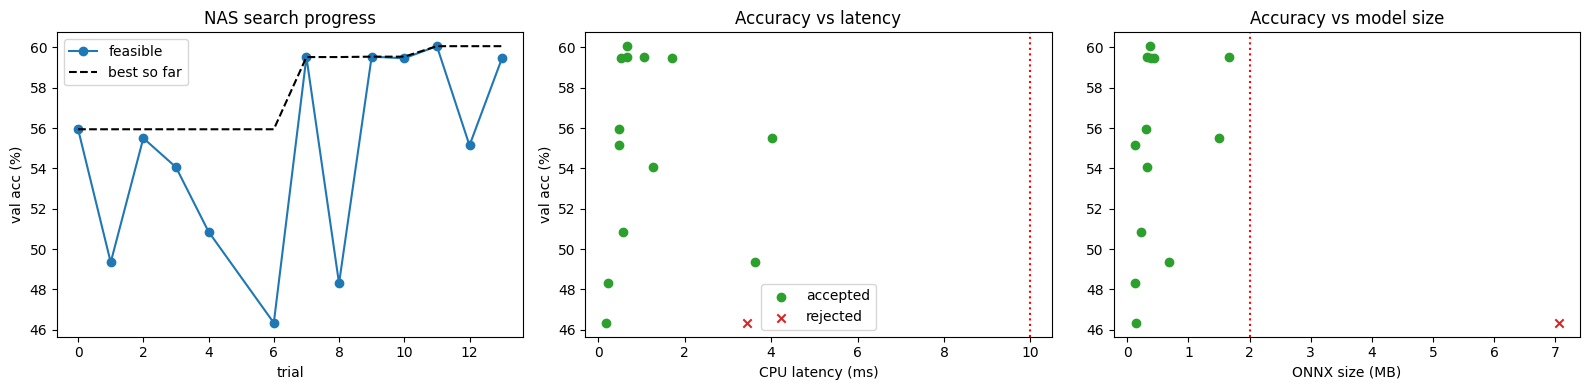

In [26]:
hist_df = pd.DataFrame(NAS_HISTORY)
feas = hist_df[hist_df.feasible == True].copy()
assert len(feas) > 0, "No feasible architecture found - relax MAX_* constraints or increase N_TRIALS."
best = feas.sort_values("score", ascending=False).iloc[0]
BEST_CFG = json.loads(best.config)
json.dump(dict(trial=int(best.trial), config=BEST_CFG, description=best.description, search_val_acc=float(best.val_acc), score=float(best.score),
               params=int(best.params), onnx_size_mb=float(best.size_mb), cpu_latency_ms=float(best.lat_mean_ms), peak_mem_mb=float(best.peak_mem_mb),
               constraints=dict(max_latency_ms=MAX_LATENCY_MS, max_size_mb=MAX_SIZE_MB, max_peak_mem_mb=MAX_PEAK_MEM_MB)),
          open(RES_DIR / "best_architecture.json", "w"), indent=2)
print("BEST ARCHITECTURE (saved to results/best_architecture.json):\n ", best.description)
print(f"  search val acc {best.val_acc:.2f}% | {best.params/1e3:.0f}k params | {best.size_mb:.2f} MB | {best.lat_mean_ms:.2f} ms | {best.peak_mem_mb:.0f} MB")

show = hist_df[["trial","description","feasible","val_acc","lat_mean_ms","size_mb","peak_mem_mb","score"]].copy(); show["description"] = show.description.str[:60]
display(show.round(3))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ok, bad = hist_df[hist_df.feasible == True], hist_df[hist_df.feasible != True]
ax[0].plot(ok.trial, ok.val_acc, "o-", label="feasible"); ax[0].set_xlabel("trial"); ax[0].set_ylabel("val acc (%)"); ax[0].set_title("NAS search progress")
ax[0].plot(ok.trial, ok.val_acc.cummax(), "k--", label="best so far"); ax[0].legend()
ax[1].scatter(ok.lat_mean_ms, ok.val_acc, c="tab:green", label="accepted"); ax[1].scatter(bad.lat_mean_ms, [ok.val_acc.min()]*len(bad), c="tab:red", marker="x", label="rejected")
ax[1].axvline(MAX_LATENCY_MS, color="r", ls=":"); ax[1].set_xlabel("CPU latency (ms)"); ax[1].set_ylabel("val acc (%)"); ax[1].set_title("Accuracy vs latency"); ax[1].legend()
ax[2].scatter(ok.size_mb, ok.val_acc, c="tab:green"); ax[2].scatter(bad.size_mb, [ok.val_acc.min()]*len(bad), c="tab:red", marker="x")
ax[2].axvline(MAX_SIZE_MB, color="r", ls=":"); ax[2].set_xlabel("ONNX size (MB)"); ax[2].set_title("Accuracy vs model size")
plt.tight_layout(); plt.savefig(FIG_DIR / "q2_nas_search.png", dpi=150); plt.show()

## 13. Train the best architecture from scratch, export to ONNX, run with ONNX Runtime
The winning config (loaded from `best_architecture.json`) is re-built, trained **from scratch** on the full 50k CIFAR-10 training set for `FINAL_EPOCHS`, and evaluated on the official 10k test set.

In [27]:
seed_all()
BEST_CFG = json.load(open(RES_DIR / "best_architecture.json"))["config"]
nas_model = NASNet(BEST_CFG, 10).to(DEV)
def nas_loss(x, y):
    out = nas_model(x); return F.cross_entropy(out, y), out
hist_nas = fit(nas_model, nas_loss, C10_FULL, C10_TE, "cifar10", FINAL_EPOCHS, 0.1, BATCH, "nas_best")
save_ckpt(nas_model, CKPT / "nas_best.pt")
pd.DataFrame(hist_nas).to_csv(RES_DIR / "nas_final_training_log.csv", index=False)
NAS_TEST_ACC = hist_nas[-1]["test_acc"]
print(f"\nNAS-discovered model: CIFAR-10 test accuracy = {NAS_TEST_ACC:.2f}%")

# ---- ONNX export + ONNX Runtime CPU inference
nas_cpu = NASNet(BEST_CFG, 10); nas_cpu.load_state_dict(torch.load(CKPT / "nas_best.pt", map_location="cpu")); nas_cpu.eval()
p = export_onnx(nas_cpu, ONNX_DIR / "nas_best.onnx")
NAS_ORT_ACC = ort_accuracy(p, C10_TE, "cifar10")
print(f"ONNX Runtime (CPU) accuracy: {NAS_ORT_ACC:.2f}% | max |logit diff| vs PyTorch: {parity(nas_cpu, p, 'cifar10', C10_TE):.2e} | file: {p.stat().st_size/2**20:.3f} MB")

demo = [C10_TE.X[i] for i in range(4)]; print("ground truth:", [C10_CLASSES[C10_TE.Y[i]] for i in range(4)])
for be in ("torch", "onnx"):
    print(f"[{be:>5}] NAS model predictions:", [q[0] for q in InferencePipeline("nas", backend=be, nas_cfg=BEST_CFG).predict(demo, topk=1)])
tick("best NAS model trained + exported")

[nas_best] ep  1/20  loss 1.655  train 38.8%  test 52.88%  (8.2s)
[nas_best] ep  2/20  loss 1.010  train 63.6%  test 55.69%  (16.4s)
[nas_best] ep  3/20  loss 0.797  train 72.0%  test 70.29%  (24.6s)
[nas_best] ep  4/20  loss 0.685  train 76.1%  test 77.06%  (33.0s)
[nas_best] ep  5/20  loss 0.610  train 78.7%  test 78.81%  (41.4s)
[nas_best] ep  6/20  loss 0.564  train 80.4%  test 78.21%  (49.6s)
[nas_best] ep  7/20  loss 0.523  train 81.9%  test 80.48%  (57.8s)
[nas_best] ep  8/20  loss 0.495  train 82.8%  test 80.26%  (66.1s)
[nas_best] ep  9/20  loss 0.460  train 84.1%  test 80.57%  (74.4s)
[nas_best] ep 10/20  loss 0.437  train 84.8%  test 83.94%  (82.6s)
[nas_best] ep 11/20  loss 0.413  train 85.9%  test 83.15%  (90.7s)
[nas_best] ep 12/20  loss 0.383  train 86.8%  test 84.54%  (99.0s)
[nas_best] ep 13/20  loss 0.359  train 87.5%  test 85.08%  (107.3s)
[nas_best] ep 14/20  loss 0.333  train 88.4%  test 85.87%  (115.6s)
[nas_best] ep 15/20  loss 0.311  train 89.4%  test 86.77%  (1

# Benchmarking, inference scripts and packaging
## 14. Automated benchmark of every deployed model (CPU, ONNX Runtime)
Accuracy (PyTorch and ONNX Runtime), parameters, ONNX file size, batch-1 latency (mean / median / p95), throughput and peak inference memory for **all 7 models** → `results/benchmark_results.csv`.

,model,task,params_M,onnx_size_mb,torch_acc,onnx_acc,lat_mean_ms,lat_median_ms,lat_p95_ms,throughput_ips,peak_mem_mb
0,baseline_mobilenetv2,Q1 CIFAR-100,2.352,8.947,65.01,65.04,3.176,3.147,3.382,314.825,40.238
1,kd_mobilenetv2,Q1 CIFAR-100,2.352,8.947,67.74,67.72,3.131,3.108,3.320,319.383,41.848
2,baseline_squeezenet,Q1 CIFAR-100,0.777,2.963,62.40,62.37,2.319,2.111,3.240,431.189,25.980
3,kd_squeezenet,Q1 CIFAR-100,0.777,2.963,63.65,63.64,2.058,2.039,2.199,485.879,24.469
4,baseline_efficientnet_lite0,Q1 CIFAR-100,3.499,13.306,66.35,66.28,3.815,3.792,4.027,262.106,50.855
5,kd_efficientnet_lite0,Q1 CIFAR-100,3.499,13.306,68.86,68.85,3.853,3.820,4.070,259.510,50.387
6,nas_best,Q2 CIFAR-10,0.096,0.368,88.00,88.01,0.695,0.666,0.885,1439.686,15.648


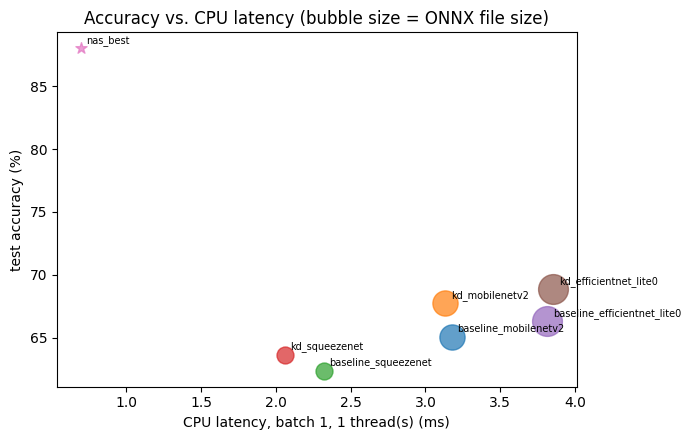

In [28]:
rows = []
for n in STUDENT_NAMES:
    for v in ("baseline", "kd"):
        p = ONNX_DIR / f"{v}_{n}.onnx"; b = bench_onnx(p); q = q1_onnx_df[q1_onnx_df.model == f"{v}_{n}"].iloc[0]
        rows.append(dict(model=f"{v}_{n}", task="Q1 CIFAR-100", params_M=count_params(build_student(n))/1e6, onnx_size_mb=p.stat().st_size/2**20,
                         torch_acc=q.torch_acc, onnx_acc=q.onnx_acc, **{k: b[k] for k in ("lat_mean_ms","lat_median_ms","lat_p95_ms","throughput_ips","peak_mem_mb")}))
p = ONNX_DIR / "nas_best.onnx"; b = bench_onnx(p)
rows.append(dict(model="nas_best", task="Q2 CIFAR-10", params_M=count_params(nas_cpu)/1e6, onnx_size_mb=p.stat().st_size/2**20,
                 torch_acc=NAS_TEST_ACC, onnx_acc=NAS_ORT_ACC, **{k: b[k] for k in ("lat_mean_ms","lat_median_ms","lat_p95_ms","throughput_ips","peak_mem_mb")}))
bench_df = pd.DataFrame(rows); bench_df.to_csv(RES_DIR / "benchmark_results.csv", index=False)
display(bench_df.round(3))

fig, ax = plt.subplots(figsize=(7, 4.5))
for _, r in bench_df.iterrows():
    ax.scatter(r.lat_mean_ms, r.onnx_acc, s=60 + 400 * r.onnx_size_mb / bench_df.onnx_size_mb.max(), alpha=.7, marker="*" if r.model == "nas_best" else "o")
    ax.annotate(r.model, (r.lat_mean_ms, r.onnx_acc), fontsize=7, xytext=(4, 4), textcoords="offset points")
ax.set_xlabel(f"CPU latency, batch 1, {BENCH_THREADS} thread(s) (ms)"); ax.set_ylabel("test accuracy (%)")
ax.set_title("Accuracy vs. CPU latency (bubble size = ONNX file size)"); plt.tight_layout(); plt.savefig(FIG_DIR / "benchmark_accuracy_vs_latency.png", dpi=150); plt.show()

## 15. Stand-alone inference script, README and submission zip

In [29]:
%%writefile assignment4_outputs/infer_onnx.py
"""Stand-alone CPU inference with ONNX Runtime for ALL exported models (6 students + NAS model).
Only needs: numpy, pillow, onnxruntime.

  python infer_onnx.py --image cat.png                       # run every model in ./onnx on one image
  python infer_onnx.py --image cat.png --model onnx/kd_mobilenetv2.onnx
  python infer_onnx.py --test-cifar                          # accuracy of every model on its CIFAR test set (needs torchvision)
"""
import argparse, json, glob, os
import numpy as np, onnxruntime as ort
from PIL import Image

HERE = os.path.dirname(os.path.abspath(__file__))
STATS = {"cifar100": ((0.5071, 0.4865, 0.4409), (0.2673, 0.2564, 0.2762)), "cifar10": ((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))}

def dataset_of(path): return "cifar10" if os.path.basename(path).startswith("nas") else "cifar100"

def normalize(batch_uint8, ds):
    m, s = STATS[ds]; x = batch_uint8.astype(np.float32) / 255.0
    return np.ascontiguousarray(((x - np.array(m, np.float32)) / np.array(s, np.float32)).transpose(0, 3, 1, 2))

def load_image(path):
    return np.array(Image.open(path).convert("RGB").resize((32, 32), Image.BILINEAR))[None]

def predict(model_path, batch, topk=3):
    ds = dataset_of(model_path); classes = json.load(open(os.path.join(HERE, "results", f"classes_{ds}.json")))
    so = ort.SessionOptions(); so.intra_op_num_threads = os.cpu_count() or 1
    sess = ort.InferenceSession(model_path, so, providers=["CPUExecutionProvider"])
    z = sess.run(None, {sess.get_inputs()[0].name: normalize(batch, ds)})[0]
    p = np.exp(z - z.max(1, keepdims=True)); p /= p.sum(1, keepdims=True)
    return [[(classes[j], float(p[i, j])) for j in np.argsort(-p[i])[:topk]] for i in range(len(p))]

def main():
    ap = argparse.ArgumentParser(); ap.add_argument("--image"); ap.add_argument("--model"); ap.add_argument("--test-cifar", action="store_true")
    a = ap.parse_args()
    models = [a.model] if a.model else sorted(glob.glob(os.path.join(HERE, "onnx", "*.onnx")))
    if a.test_cifar:
        from torchvision.datasets import CIFAR10, CIFAR100
        for m in models:
            ds = dataset_of(m); D = CIFAR10 if ds == "cifar10" else CIFAR100; te = D(os.path.join(HERE, "data"), train=False, download=True)
            sess = ort.InferenceSession(m, providers=["CPUExecutionProvider"]); name = sess.get_inputs()[0].name; c = 0
            for i in range(0, len(te.data), 250):
                c += int((sess.run(None, {name: normalize(te.data[i:i+250], ds)})[0].argmax(1) == np.array(te.targets[i:i+250])).sum())
            print(f"{os.path.basename(m):<34} {ds:<9} test acc = {100*c/len(te.data):.2f}%")
        return
    img = load_image(a.image)
    for m in models:
        print(f"{os.path.basename(m):<34}", [f"{l} ({p:.2f})" for l, p in predict(m, img)[0]])

if __name__ == "__main__":
    main()

Writing assignment4_outputs/infer_onnx.py


In [30]:
# ---- save a few sample images and run the stand-alone script on them (end-to-end deployment check)
(OUT / "samples").mkdir(exist_ok=True)
for i in range(3):
    Image.fromarray(C100_TE.X[i]).resize((128, 128)).save(OUT / "samples" / f"cifar100_test_{i}_{C100_CLASSES[C100_TE.Y[i]]}.png")
Image.fromarray(C10_TE.X[0]).resize((128, 128)).save(OUT / "samples" / f"cifar10_test_0_{C10_CLASSES[C10_TE.Y[0]]}.png")
shutil.copy("benchmark_onnx.py", OUT / "benchmark_onnx.py")
sample = sorted((OUT / "samples").glob("cifar100_test_0_*.png"))[0]
r = subprocess.run([sys.executable, str(OUT / "infer_onnx.py"), "--image", str(sample)], capture_output=True, text=True)
print(f"$ python infer_onnx.py --image {sample.name}\n" + (r.stdout or r.stderr))

$ python infer_onnx.py --image cifar100_test_0_mountain.png
baseline_efficientnet_lite0.onnx   ['sea (0.21)', 'road (0.15)', 'dolphin (0.07)']
baseline_mobilenetv2.onnx          ['seal (0.16)', 'otter (0.10)', 'man (0.08)']
baseline_squeezenet.onnx           ['dolphin (0.25)', 'road (0.18)', 'seal (0.14)']
kd_efficientnet_lite0.onnx         ['road (0.94)', 'sea (0.02)', 'skyscraper (0.01)']
kd_mobilenetv2.onnx                ['road (0.91)', 'sea (0.05)', 'plain (0.01)']
kd_squeezenet.onnx                 ['road (0.59)', 'man (0.08)', 'dolphin (0.07)']
nas_best.onnx                      ['bird (0.88)', 'airplane (0.09)', 'dog (0.01)']



In [31]:
readme = f"""# Assignment 4 - Edge Computing & Intelligent Systems  ({ROLL_NUM}_{SECTION})

Q1: Knowledge distillation (ResNet-50 teacher -> MobileNetV2 / SqueezeNet / EfficientNet-Lite0, CIFAR-100) + ONNX Runtime CPU inference.
Q2: Hardware-aware NAS with Optuna (CIFAR-10) measured on real CPU latency / size / memory + ONNX Runtime CPU inference.

## Requirements
Python >= 3.10, PyTorch, torchvision, onnx, onnxruntime, onnxscript, optuna, numpy, pandas, matplotlib, pillow, psutil.
`pip install torch torchvision onnx onnxruntime onnxscript optuna numpy pandas matplotlib pillow psutil`
Training used a Kaggle GPU runtime (T4, fp16 mixed precision). The notebook falls back to CPU automatically (very slow).

## How to run (training + everything)
1. Import `Assignment4_Edge_KD_NAS_Kaggle.ipynb` into Kaggle; Session options: Accelerator = GPU, Internet = On.
2. `Run All`. CIFAR-10/100 and ImageNet-pretrained ResNet-50 weights are downloaded by the notebook.
   Set `QUICK = True` in the configuration cell for a few-minute smoke test.
3. Outputs are written to `assignment4_outputs/` (layout below).

## How to run inference only (no training, CPU)
```
cd assignment4_outputs
python infer_onnx.py --image samples/<any image>.png                 # all 7 ONNX models
python infer_onnx.py --image my.jpg --model onnx/kd_mobilenetv2.onnx # one model
python infer_onnx.py --test-cifar                                    # test-set accuracy of every model through ONNX Runtime
python benchmark_onnx.py onnx/nas_best.onnx --runs 200 --threads 1   # latency / throughput / peak memory
```

## Layout
| Path | Deliverable |
|---|---|
| `checkpoints/teacher_resnet50.pt` | 1. Teacher checkpoint (training script = notebook sec. 4) |
| notebook sec. 3 | 2. Student architectures (MobileNetV2, SqueezeNet, EfficientNet-Lite0) |
| `checkpoints/baseline_*.pt` | 3. Baseline students (sec. 5) |
| `checkpoints/kd_*.pt` | 4. Distilled students + KD implementation (sec. 6) |
| notebook sec. 10 | 5. NAS search space + architecture generator |
| notebook sec. 12 | 6. Optuna (TPE) search |
| `results/nas_search_history.csv/json`, `results/best_architecture.json` | 7. NAS results |
| `checkpoints/nas_best.pt` | 8. Optimised architecture checkpoint |
| `infer_onnx.py`, notebook sec. 8 (`InferencePipeline`) | 9. Inference pipeline |
| `onnx/*.onnx` | 10. ONNX models (+ ONNX Runtime CPU scripts) |
| `benchmark_onnx.py`, `results/benchmark_results.csv` | 11. Benchmarking |
| `figures/*.png`, `results/*.csv` | material for the technical report (12) |

## Key results
{bench_df.round(3).to_markdown(index=False)}

Teacher ResNet-50 (CIFAR-100): {TEACHER_ACC:.2f}%.   KD hyper-parameters: T={KD_T}, alpha={KD_ALPHA}, beta(feature)={KD_BETA}.
NAS constraints: latency <= {MAX_LATENCY_MS} ms, size <= {MAX_SIZE_MB} MB, peak memory <= {MAX_PEAK_MEM_MB} MB. Best architecture: {json.load(open(RES_DIR/'best_architecture.json'))['description']}
"""
(OUT / "README.md").write_text(readme)

# results summary (copy numbers straight into the PDF report)
with open(RES_DIR / "results_summary.md", "w") as f:
    f.write(f"## Q1: baseline vs distillation (teacher {TEACHER_ACC:.2f}%)\n\n{cmp_df.to_markdown(index=False)}\n\n## ONNX validation\n\n{q1_onnx_df.round(4).to_markdown(index=False)}\n\n## Benchmark\n\n{bench_df.round(3).to_markdown(index=False)}\n")
shutil.rmtree(NAS_DIR, ignore_errors=True)

ZIP_NAME = f"{ROLL_NUM}_{SECTION}"
shutil.make_archive(ZIP_NAME, "zip", root_dir=".", base_dir=str(OUT))
print(f"Created {ZIP_NAME}.zip  ({os.path.getsize(ZIP_NAME + '.zip')/2**20:.1f} MB)")
print(f"Download it from the notebook Output tab: /kaggle/working/{ZIP_NAME}.zip")
tick("ALL DONE")

Created 21i-1713_A.zip  (179.6 MB)
Download it from the notebook Output tab: /kaggle/working/21i-1713_A.zip

>>> [ 54.2 min elapsed] ALL DONE



## 16. Notes for the technical report
* **Teacher:** ImageNet-pretrained ResNet-50 with a CIFAR stem, fine-tuned for `TEACHER_EPOCHS`.
* **Fair comparison:** baseline and KD students share seed, schedule, epochs, augmentation and optimiser; the only difference is the loss.
* **GPU specifics:** fp16 autocast + GradScaler, channels-last, cuDNN autotune, fixed batch shapes; the teacher keeps its stem max-pool to cut compute (document this in the report).
* **NAS cost saving:** infeasible architectures are rejected from *measured* CPU latency / size / memory before any training.
* **Latency protocol:** ONNX Runtime CPUExecutionProvider, batch 1, `BENCH_THREADS` threads, warm-up + `BENCH_RUNS` timed runs, measured in a clean subprocess. Peak memory = growth of process RSS during inference (Linux).
* Screenshots to include in the PDF: training logs, `figures/*.png`, the benchmark table, the NAS history table and the `infer_onnx.py` output.